(mmm_price_floor)=

# Budget cuts when media prices have a floor

An auction price response can be asymmetric. Buying more inventory may bid up
prices, while cutting the budget may leave minimum bids and floor prices unchanged.
The symmetric `PowerPriceResponse` assumes prices fall below the reference as well
as rise above it. On a small plan that assumption can make an expensive channel
look attractive because the optimizer expects to buy its first units cheaply.

This example compares constant prices, symmetric bid-up, and a price floor using
`flat_below_reference=True`. We use stipulated response curves and one fixed
parameter draw to isolate the planning mechanism. These are **synthetic assumptions**,
not a fitted model, evidence about any real channel, or recommended elasticities.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pymc.dims as pmd
import pytensor.xtensor as ptx
import xarray as xr
from pytensor.xtensor import as_xtensor

from pymc_marketing.mmm import BudgetOptimizer, PowerPriceResponse

channels = ["search", "social", "premium_video"]
dates = pd.date_range("2026-01-05", periods=4, freq="W-MON")
coords = {"date": dates, "channel": channels}
base_price = xr.DataArray(
    np.tile([2.0, 3.0, 80.0], (4, 1)), dims=("date", "channel"), coords=coords
)
reference = xr.DataArray(
    [100.0, 100.0, 100.0], dims="channel", coords={"channel": channels}
)

with pm.Model(coords=coords) as model:
    delivery = pmd.Data("channel_data", np.ones((4, 3)), dims=("date", "channel"))
    beta = pmd.HalfNormal("beta", sigma=20, dims="channel")
    contribution = pmd.Deterministic(
        "channel_contribution",
        beta * ptx.math.log1p(delivery),
        dims=("date", "channel"),
    )
    pmd.Deterministic("total_media_contribution_original_scale", contribution.sum())

# One fixed draw represents our stipulated response, without sampling or fitting.
idata = xr.DataTree.from_dict(
    {
        "posterior": xr.Dataset(
            {"beta": (("chain", "draw", "channel"), [[[12.0, 8.0, 3.0]]])},
            coords={"chain": [0], "draw": [0], "channel": channels},
        )
    }
)

/Users/alifozooni/Desktop/Personal/pymc-marketing-price-floor/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Compare the buying assumptions

Let $s$ be per-week money, $p_0$ the base cost per delivery unit,
$s_{\rm ref}$ the reference spend and $\gamma$ the assumed price elasticity.
Outside the small smoothing regions:

- **Constant:** $p(s)=p_0$.
- **Symmetric bid-up:** $p(s)=p_0(s/s_{\rm ref})^\gamma$.
- **Floor:** $p(s)=p_0\max(s/s_{\rm ref},1)^\gamma$.

Delivery is $u(s)=s/p(s)$. The floor variant uses a concave quadratic near the
reference so delivery and its first derivative are continuous. `knee_sharpness=100`
puts this transition at roughly 99%–101% of the reference. A sharper knee narrows
the approximation but increases curvature. Through the blend the price can slightly
exceed the unsmoothed price; it never falls below $p_0$.

The `assume_delivery_units=True` flag attests that the response graph takes physical
delivery units. This remains necessary for the floor variant because its upper
branch still adds price curvature. Adding it to a saturation curve fitted on nominal
spend can count that curvature twice.

In [2]:
optimizers = {}
results = {}
for name, floor in [
    ("Constant", None),
    ("Symmetric bid-up", False),
    ("Price floor", True),
]:
    response = (
        None
        if floor is None
        else PowerPriceResponse(
            elasticity=0.5,
            reference_spend=reference,
            assume_delivery_units=True,
            flat_below_reference=floor,
            knee_sharpness=100,
        )
    )
    optimizer = BudgetOptimizer(
        model=model,
        idata=idata,
        num_periods=4,
        cost_per_unit=base_price,
        price_response=response,
    )
    optimizers[name] = optimizer
    results[name] = optimizer.allocate_budget(
        total_budget=100.0,
        budget_bounds={channel: (0.0, 100.0) for channel in channels},
    )

pd.DataFrame(
    {name: result.budgets.to_series() for name, result in results.items()}
).round(3)

,Constant,Symmetric bid-up,Price floor
channel,,,
search,61.0,59.005,61.0
social,39.0,38.499,39.0
premium_video,0.0,2.496,0.0


The budget is 100 **per week**, so the four-week commitment is 400. The expensive
video channel is unattractive at its base price. The symmetric response can still
fund it by predicting cheap units on a small buy; the floor removes that mechanism.
The other allocations also depend on the buying assumption.

The symmetric variant remains useful if smaller buys really can access cheaper
inventory. Choose the shape using buying evidence and compare plausible elasticities.
A floor is a planning scenario, not an estimate of auction dynamics.

In [3]:
price_comparison = pd.DataFrame(
    {
        name: results[name].implied_price.mean("date").to_series()
        for name in ["Symmetric bid-up", "Price floor"]
    }
)
price_comparison["Base price"] = base_price.isel(date=0).to_series()
price_comparison.round(3)

,Symmetric bid-up,Price floor,Base price
channel,,,
search,1.536,2.0,2.0
social,1.861,3.0,3.0
premium_video,12.639,NaN,80.0


A price is missing when no unit was bought. Read `implied_delivery`,
`implied_price`, and `implied_marginal_price` together: the latter is the cost of
the next unit, which is what matters for allocation. The response used to score a
plan must include the same price map that was used to optimize it.

In [4]:
floored = results["Price floor"]
weekly_money = (floored.implied_delivery * floored.implied_price).fillna(0)
pd.DataFrame(
    {
        "Allocated window money": floored.budgets.to_series() * 4,
        "Delivery times price": weekly_money.sum("date").to_series(),
    }
).round(6)

,Allocated window money,Delivery times price
channel,,
search,244.000002,244.000002
social,155.999998,155.999998
premium_video,0.000000,0.000000


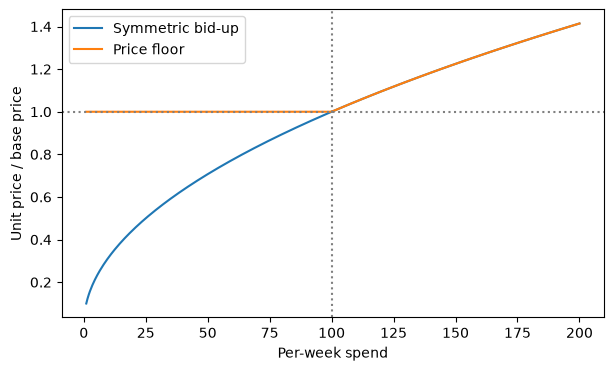

In [5]:
spend_grid = np.linspace(1, 200, 400)
fig, ax = plt.subplots(figsize=(7, 4))
for name, floor in [("Symmetric bid-up", False), ("Price floor", True)]:
    resolved = PowerPriceResponse(
        elasticity=0.5, reference_spend=reference, flat_below_reference=floor
    ).resolve(
        dims=("channel",),
        coords={"channel": channels},
        mask=xr.ones_like(reference, dtype=bool),
        date_dim="date",
        derived_reference=None,
        label="price comparison",
    )
    money = as_xtensor(np.tile(spend_grid[:, None], (1, 3)), dims=("date", "channel"))
    price_ratio = resolved.implied_price(money).eval()[:, 0]
    ax.plot(spend_grid, price_ratio, label=name)
ax.axhline(1, color="grey", linestyle=":")
ax.axvline(100, color="grey", linestyle=":")
ax.set(xlabel="Per-week spend", ylabel="Unit price / base price")
ax.legend()
plt.show()

The floor is linear at zero, so the default variant's `max_slope_ratio` setting
has no effect here; `knee_sharpness` controls the transition instead. Both variants
retain the same reference-spend alignment, unit checks, and money constraints.
For date-varying prices or flighting, the map acts on each period's money after
redistribution, so inspect period-level delivery rather than pricing the average buy.

In [6]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing

Last updated: Sun, 08 Nov 2026

Python implementation: CPython
Python version       : 3.12.7
IPython version      : 9.18.1

pymc_marketing: 1.3.0

matplotlib    : 3.11.2
numpy         : 2.5.4
pandas        : 3.1.1
pymc          : 6.4.0
pymc_marketing: 1.3.0
pytensor      : 3.3.8
xarray        : 2026.9.0

Watermark: 2.6.0

